£ 1,000: median 0.00% | P(0 prizes) 56.6% | 25th-75th pct: 0.00% to 5.00%| P(beat 3.8%) 35.0%
£15,000: median 3.50% | P(0 prizes) 0.0% | 25th-75th pct: 2.67% to 4.83%| P(beat 3.8%) 45.6%
£40,000: median 3.75% | P(0 prizes) 0.0% | 25th-75th pct: 3.06% to 4.56%| P(beat 3.8%) 49.1%


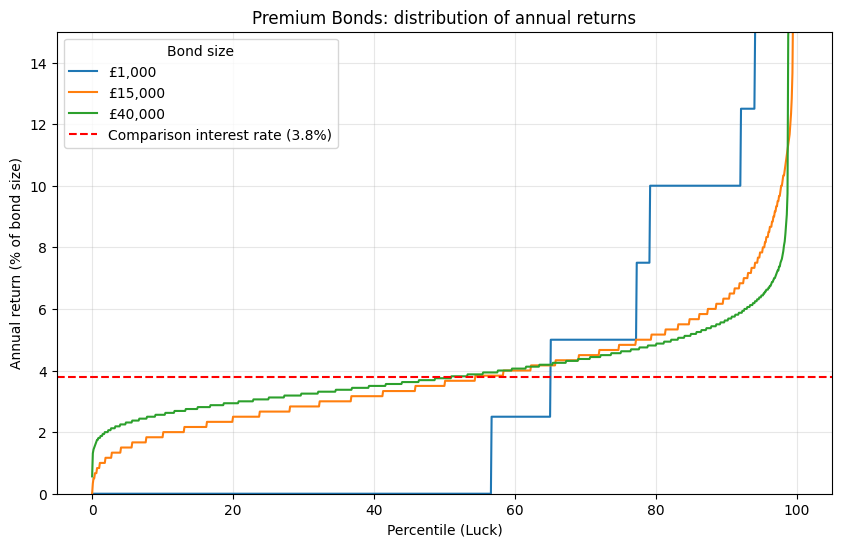

In [1]:
import numpy as np
import matplotlib.pyplot as plt

TOTAL_BONDS = 137_483_797_618

prize_values = np.array([25, 50, 100, 500, 1_000, 5_000, 10_000, 25_000, 50_000, 100_000])
prize_counts = np.array([1_721_281, 2_371_145, 2_371_145, 59_802, 19_934,
                         1_914, 957, 382, 191, 96])

p_prizes = prize_counts / TOTAL_BONDS
probs = np.concatenate(([1 - p_prizes.sum()], p_prizes))
values = np.concatenate(([0], prize_values))

rng = np.random.default_rng(42)


def annual_returns(bond_size, n_sims=100_000, months=12):
    counts = rng.multinomial(bond_size * months, probs, size=n_sims)
    total_won = counts @ values
    return 100 * total_won / bond_size


bond_sizes = [1_000, 15_000, 40_000]
interest_rate = 3.8
percentiles = np.linspace(0, 100, 1001)

fig, ax = plt.subplots(figsize=(10, 6))
for size in bond_sizes:
    returns = annual_returns(size)
    ax.plot(percentiles, np.percentile(returns, percentiles), label=f"£{size:,}")

    print(f"£{size:>6,}: median {np.median(returns):.2f}% "
          f"| P(0 prizes) {np.mean(returns == 0):.1%} "
          f"| 25th-75th pct: {np.percentile(returns, 25):.2f}% to {np.percentile(returns, 75):.2f}%"
          f"| P(beat {interest_rate}%) {np.mean(returns > interest_rate):.1%}")

ax.axhline(interest_rate, color="red", linestyle="--", linewidth=1.5,
           label=f"Comparison interest rate ({interest_rate}%)")

ax.set_xlabel("Percentile (Luck)")
ax.set_ylabel("Annual return (% of bond size)")
ax.set_title("Premium Bonds: distribution of annual returns")
ax.set_ylim(0, 15)
ax.grid(alpha=0.3)
ax.legend(title="Bond size")
plt.show()

Breakpoint: ~£15,750
  Premium bonds (25th / 50th / 75th pct): 2.70% / 3.65% / 4.76%  (£425 / £575 / £750)
  Fixed saver post-tax: 3.55%  (£559)
Tax above £13,158


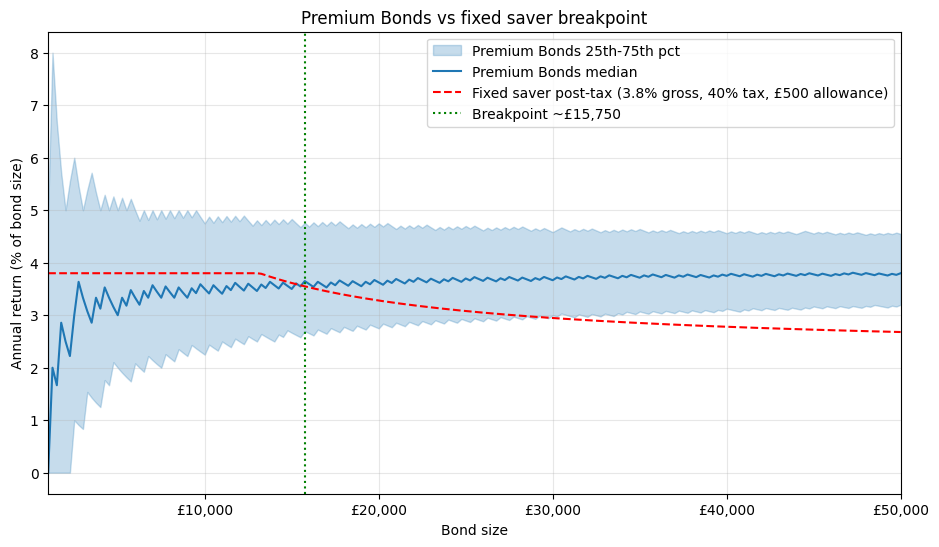

In [2]:
# Breakpoint
TAX_RATE = 0.40        # marginal tax rate
ALLOWANCE = 500      # Personal Savings Allowance

SIZE_MIN, SIZE_MAX, SIZE_STEP = 1_000, 50_000, 250
N_SIMS = 100_000


def savings_net_return(size, rate=interest_rate, tax_rate=TAX_RATE, allowance=ALLOWANCE):
    interest = size * rate / 100
    tax = tax_rate * np.maximum(0, interest - allowance)
    return 100 * (interest - tax) / size


sizes = np.arange(SIZE_MIN, SIZE_MAX + 1, SIZE_STEP)
p25, p50, p75 = np.empty(len(sizes)), np.empty(len(sizes)), np.empty(len(sizes))

for i, size in enumerate(sizes):
    r = annual_returns(size, n_sims=N_SIMS)
    p25[i], p50[i], p75[i] = np.percentile(r, [25, 50, 75])

net_savings = savings_net_return(sizes)

# Breakpoint: smallest size from which the bond median beats the post-tax saver
beats = p50 > net_savings
sustained = np.flip(np.cumprod(np.flip(beats))).astype(bool)

if sustained.any():
    idx = np.argmax(sustained)
    breakpoint_size = sizes[idx]
    print(f"Breakpoint: ~£{breakpoint_size:,}")
    print(f"  Premium bonds (25th / 50th / 75th pct): "
          f"{p25[idx]:.2f}% / {p50[idx]:.2f}% / {p75[idx]:.2f}%  "
          f"(£{p25[idx]*breakpoint_size/100:,.0f} / £{p50[idx]*breakpoint_size/100:,.0f} / "
          f"£{p75[idx]*breakpoint_size/100:,.0f})")
    print(f"  Fixed saver post-tax: {net_savings[idx]:.2f}%  "
          f"(£{net_savings[idx]*breakpoint_size/100:,.0f})")
else:
    breakpoint_size = None
    print("No breakpoint found in this size range with these inputs.")

tax_threshold = ALLOWANCE / (interest_rate / 100)
print(f"Tax above £{tax_threshold:,.0f}")


fig, ax = plt.subplots(figsize=(11, 6))
ax.fill_between(sizes, p25, p75, alpha=0.25, color="tab:blue", label="Premium Bonds 25th-75th pct")
ax.plot(sizes, p50, color="tab:blue", label="Premium Bonds median")
ax.plot(sizes, net_savings, color="red", linestyle="--",
        label=f"Fixed saver post-tax ({interest_rate}% gross, {TAX_RATE:.0%} tax, £{ALLOWANCE} allowance)")

if breakpoint_size is not None:
    ax.axvline(breakpoint_size, color="green", linestyle=":", linewidth=1.5,
               label=f"Breakpoint ~£{breakpoint_size:,}")

ax.set_xlabel("Bond size")
ax.set_ylabel("Annual return (% of bond size)")
ax.set_title("Premium Bonds vs fixed saver breakpoint")
ax.set_xlim(SIZE_MIN, SIZE_MAX)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"£{x:,.0f}"))
ax.grid(alpha=0.3)
ax.legend()
plt.show()